<a href="https://colab.research.google.com/github/anweshatripathy37-debug/A-python/blob/main/Dmpm_lab_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Classification using Decision Tree Induction

Decision Trees are a non-parametric supervised learning method used for classification and regression. The goal is to create a model that predicts the value of a target variable by learning simple decision rules inferred from the data features.

First, we need to prepare our synthetic weather dataset. The `Outlook` target variable is categorical, so we'll need to convert it into numerical format using `LabelEncoder`. We also need to separate our features (X) from our target (y).

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# Assuming weather_df from previous steps is available
# If not, regenerate it:
num_samples = 100
np.random.seed(42)
temperatures = np.random.uniform(10, 35, num_samples)
humidity = np.random.uniform(30, 95, num_samples)
wind_speed = np.random.uniform(0, 30, num_samples)
outlook = []
for i in range(num_samples):
    if temperatures[i] > 25 and humidity[i] < 60:
        outlook.append('Sunny')
    elif humidity[i] > 75 or wind_speed[i] > 20:
        outlook.append('Rainy')
    else:
        outlook.append('Cloudy')
weather_df = pd.DataFrame({
    'Temperature': temperatures,
    'Humidity': humidity,
    'Wind_Speed': wind_speed,
    'Outlook': outlook
})

# Separate features (X) and target (y)
X_weather = weather_df[['Temperature', 'Humidity', 'Wind_Speed']]
y_weather_categorical = weather_df['Outlook']

# Encode the categorical target variable
le = LabelEncoder()
y_weather = le.fit_transform(y_weather_categorical)

print("Original Outlook categories:", le.classes_)
print("Encoded target (y) samples:\n", y_weather[:5])

# Split the dataset into training and testing sets
X_train_weather, X_test_weather, y_train_weather, y_test_weather = train_test_split(
    X_weather, y_weather, test_size=0.3, random_state=42, stratify=y_weather)

print(f"\nTraining features shape: {X_train_weather.shape}")
print(f"Testing features shape: {X_test_weather.shape}")

Original Outlook categories: ['Cloudy' 'Rainy' 'Sunny']
Encoded target (y) samples:
 [0 0 2 1 1]

Training features shape: (70, 3)
Testing features shape: (30, 3)


Now, let's train a `DecisionTreeClassifier` and evaluate its performance.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize the Decision Tree Classifier
dtree_classifier = DecisionTreeClassifier(random_state=42)

# Train the model
dtree_classifier.fit(X_train_weather, y_train_weather)

# Make predictions on the test set
y_pred_weather = dtree_classifier.predict(X_test_weather)

# Evaluate the model
accuracy = accuracy_score(y_test_weather, y_pred_weather)
print(f"Decision Tree Classifier Accuracy: {accuracy:.2f}")

print("\nClassification Report:")
print(classification_report(y_test_weather, y_pred_weather, target_names=le.classes_))

print("\nFirst 10 Actual vs. Predicted values (Encoded):")
for i in range(10):
    actual_label = le.inverse_transform([y_test_weather[i]])[0]
    predicted_label = le.inverse_transform([y_pred_weather[i]])[0]
    print(f"Actual: {actual_label}, Predicted: {predicted_label}")

Decision Tree Classifier Accuracy: 1.00

Classification Report:
              precision    recall  f1-score   support

      Cloudy       1.00      1.00      1.00         9
       Rainy       1.00      1.00      1.00        15
       Sunny       1.00      1.00      1.00         6

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


First 10 Actual vs. Predicted values (Encoded):
Actual: Rainy, Predicted: Rainy
Actual: Rainy, Predicted: Rainy
Actual: Rainy, Predicted: Rainy
Actual: Rainy, Predicted: Rainy
Actual: Rainy, Predicted: Rainy
Actual: Sunny, Predicted: Sunny
Actual: Cloudy, Predicted: Cloudy
Actual: Cloudy, Predicted: Cloudy
Actual: Rainy, Predicted: Rainy
Actual: Sunny, Predicted: Sunny


### Visualizing the Decision Tree

We can visualize the decision tree to understand how it makes predictions. `Scikit-learn` provides tools to plot the tree and also to get a text representation of its rules.

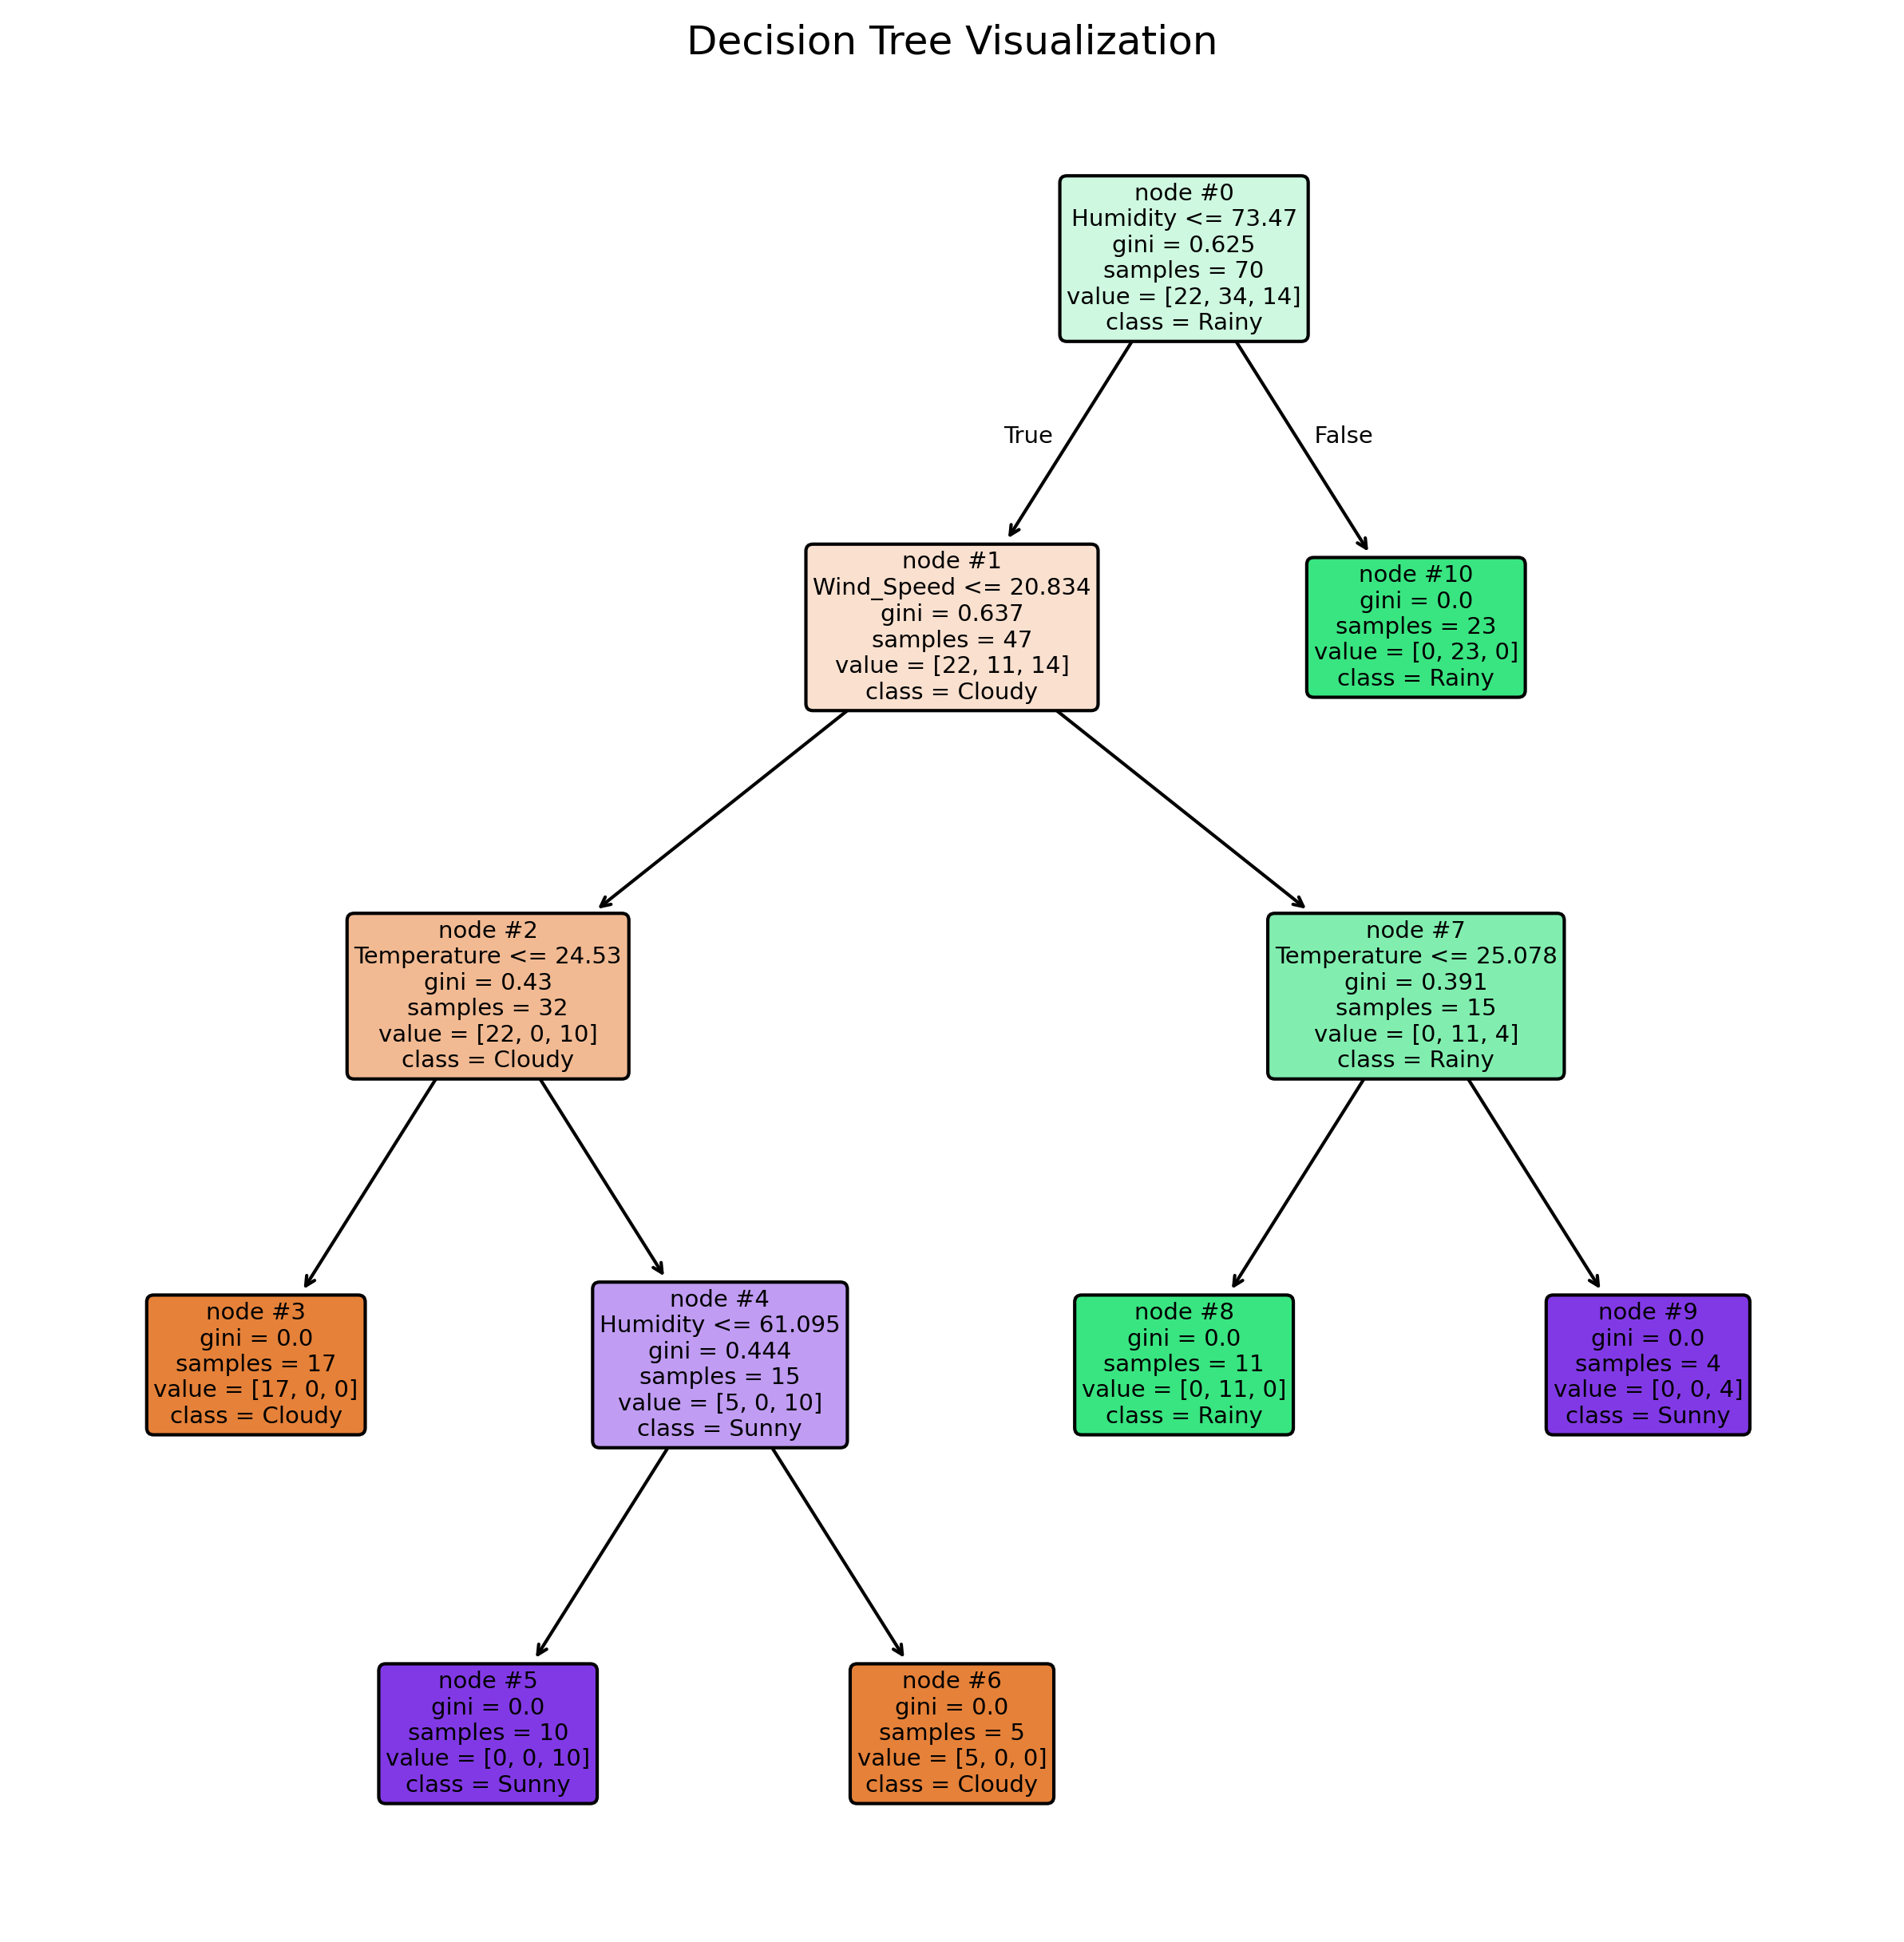


Text-based Decision Tree Rules:
|--- Humidity <= 73.47
|   |--- Wind_Speed <= 20.83
|   |   |--- Temperature <= 24.53
|   |   |   |--- class: Cloudy
|   |   |--- Temperature >  24.53
|   |   |   |--- Humidity <= 61.09
|   |   |   |   |--- class: Sunny
|   |   |   |--- Humidity >  61.09
|   |   |   |   |--- class: Cloudy
|   |--- Wind_Speed >  20.83
|   |   |--- Temperature <= 25.08
|   |   |   |--- class: Rainy
|   |   |--- Temperature >  25.08
|   |   |   |--- class: Sunny
|--- Humidity >  73.47
|   |--- class: Rainy



In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, export_text

# Visualize the decision tree
fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (10,10), dpi=300)
plot_tree(dtree_classifier,
          feature_names = X_weather.columns,
          class_names = le.classes_,
          filled = True, rounded = True,
          proportion = False,
          node_ids = True,
          fontsize = 7);
plt.title('Decision Tree Visualization')
plt.show()

# Print the text representation of the tree
print("\nText-based Decision Tree Rules:")
print(export_text(dtree_classifier, feature_names=list(X_weather.columns), class_names=list(le.classes_)))